# Procesamiento Big Data y análisis de sentimiento con Apache Spark y AWS

## 1. Descripción del proyecto

Este proyecto desarrolla flujos de procesamiento distribuido de datos y análisis de sentimiento utilizando Apache Spark, PySpark y servicios de Amazon Web Services (AWS).

El trabajo se centra en el análisis del conjunto de datos público Amazon Customer Reviews, combinando procesamiento por lotes, transformación de texto, aprendizaje automático y procesamiento de eventos en tiempo real.

La solución aborda dos arquitecturas complementarias:

- **Procesamiento por lotes (Batch Processing):** ingesta y transformación de datos de reseñas de clientes, análisis exploratorio, limpieza y preparación de texto, entrenamiento y evaluación de modelos de clasificación con Spark ML, persistencia de modelos en Amazon S3 y ejecución de inferencias batch.
  
- **Procesamiento en tiempo real (Stream Processing):** ingesta de eventos mediante Amazon Kinesis Data Streams, procesamiento con Spark Structured Streaming, decodificación de mensajes JSON e integración con Amazon Comprehend para el análisis de sentimiento. Se incluye también una implementación local de streaming para generar y procesar eventos mediante Spark.

El proyecto cubre distintas etapas de un flujo de ingeniería de datos: ingesta, transformación, procesamiento distribuido, análisis, aprendizaje automático, almacenamiento en cloud y procesamiento de eventos.

## Tecnologías utilizadas

### Cloud y Big Data
- Amazon Web Services (AWS)
- Amazon EMR
- Amazon S3
- Amazon Kinesis Data Streams
- Amazon Comprehend
- Apache Spark
- PySpark
- Spark Structured Streaming
- Spark ML

### Programación y análisis
- Python
- SQL
- Boto3
- Pandas
- NumPy
- Parquet
- TSV

### Análisis y visualización
- Matplotlib
- Seaborn

## Fuente de datos

Se utiliza el conjunto de datos público Amazon Customer Reviews, centrado en la categoría de productos Electronics.

El conjunto contiene información sobre el texto de las reseñas, las valoraciones de los clientes, los identificadores de producto y las fechas de publicación.

El flujo batch de esta versión utiliza una copia local del conjunto de datos en formato TSV. Amazon S3 se utiliza para almacenar y recuperar los modelos entrenados. La arquitectura de datos original también contempla el uso de archivos Parquet almacenados en S3.

## Arquitectura del proyecto

El proyecto comprende dos líneas de procesamiento:

**Procesamiento por lotes:**

Amazon Customer Reviews → PySpark → Limpieza y transformación → Análisis exploratorio → Preparación de características → Pipelines de Spark ML → Entrenamiento y evaluación → Persistencia de modelos en Amazon S3 → Inferencia batch.

**Procesamiento en tiempo real:**

Amazon Kinesis Data Streams → Spark Structured Streaming → Decodificación de eventos → Interpretación de mensajes JSON → Amazon Comprehend.

Como complemento, se incluye una implementación local de Structured Streaming que utiliza la fuente rate para generar eventos, procesar mensajes JSON y clasificarlos mediante una función UDF de Python.

## 2. Configuración del entorno

El proyecto contempla la ejecución de procesos distribuidos mediante Apache Spark en un clúster de Amazon EMR, así como la ejecución local de los flujos de procesamiento compatibles.

Para ejecutar los componentes integrados con AWS, es necesario disponer de:

- Un entorno de Amazon EMR con Apache Spark instalado y configurado.

- Permisos IAM para acceder a los recursos de Amazon S3 y Amazon Kinesis Data Streams.

- El conector de Spark para Kinesis compatible con las versiones de Spark y Scala del entorno.

- Permisos IAM adicionales para invocar Amazon Comprehend cuando se utilice el análisis de sentimiento mediante este servicio.

La autenticación con AWS se realiza mediante el mecanismo de credenciales y roles configurado en el entorno de ejecución. No se incluyen claves ni credenciales directamente en el notebook.

Para la ejecución local, se requiere Python, Java y PySpark, junto con las dependencias necesarias para los procesos de análisis y streaming.

In [1]:
# Importación de librerías

import os
import sys
import shutil
import json
import re
import boto3

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import (
    StructType,
    StructField,
    StringType
)

from pyspark.ml import Pipeline, PipelineModel

from pyspark.ml.feature import (
    Tokenizer,
    StopWordsRemover,
    HashingTF,
    IDF
)

from pyspark.ml.classification import (
    LogisticRegression,
    DecisionTreeClassifier
)

from pyspark.ml.evaluation import BinaryClassificationEvaluator

from pyspark.sql.functions import udf

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


In [2]:
# Configuración de almacenamiento de modelos en Amazon S3

S3_BUCKET_NAME = "your-s3-bucket-name" # tu bucket de s3 donde se guardarán los modelos

S3_MODEL_PATH_LOGISTIC_REGRESSION = (
    f"s3a://{S3_BUCKET_NAME}/models/sentiment_logistic_regression"
)

S3_MODEL_PATH_DECISION_TREE = (
    f"s3a://{S3_BUCKET_NAME}/models/sentiment_decision_tree"
)


In [3]:
# Configuración de Hadoop para ejecución local en Windows

HADOOP_HOME = r"C:\hadoop"
HADOOP_BIN = os.path.join(HADOOP_HOME, "bin")
WINUTILS_PATH = os.path.join(HADOOP_BIN, "winutils.exe")

os.environ["HADOOP_HOME"] = HADOOP_HOME
os.environ["PATH"] = (
    HADOOP_BIN + os.pathsep + os.environ.get("PATH", "")
)

if os.path.isfile(WINUTILS_PATH):
    print("Configuración local de Hadoop completada.")
else:
    print(f"Advertencia: no se encuentra winutils.exe en {WINUTILS_PATH}")


Configuración local de Hadoop completada.


### 2.1. Inicialización de Apache Spark

In [4]:
# Configuración del intérprete de Python
PYTHON_EXECUTABLE = sys.executable

os.environ["PYSPARK_PYTHON"] = PYTHON_EXECUTABLE
os.environ["PYSPARK_DRIVER_PYTHON"] = PYTHON_EXECUTABLE

# Inicialización de Spark en modo local
spark = (
    SparkSession.builder
    .master("local[1]")
    .appName("AmazonReviewsBigDataAnalysis")
    .config("spark.pyspark.python", PYTHON_EXECUTABLE)
    .config("spark.pyspark.driver.python", PYTHON_EXECUTABLE)
    .config("spark.driver.host", "127.0.0.1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .config(
        "spark.jars.packages",
        "org.apache.hadoop:hadoop-aws:3.5.0,"
        "software.amazon.awssdk:bundle:2.25.53"
    )
    .config(
        "spark.hadoop.fs.s3a.impl",
        "org.apache.hadoop.fs.s3a.S3AFileSystem"
    )
    .config(
        "spark.hadoop.fs.s3a.aws.credentials.provider",
        "software.amazon.awssdk.auth.credentials.DefaultCredentialsProvider"
    )
    .config("spark.hadoop.fs.s3a.endpoint.region", "us-east-1")
    .getOrCreate()
)

# Información del entorno de ejecución
print(f"Versión de Apache Spark: {spark.version}")
print(
    "Versión de Hadoop:",
    spark.sparkContext._jvm.org.apache.hadoop.util.VersionInfo.getVersion()
)

Versión de Apache Spark: 4.2.0
Versión de Hadoop: 3.5.0


## 3. Ingesta de datos por lotes

En esta fase se realiza la carga del conjunto de datos público Amazon Customer Reviews, que contiene reseñas y valoraciones de productos publicadas por clientes de Amazon.

Los datos se leen desde un archivo local en formato TSV (valores separados por tabuladores) mediante Apache Spark, aprovechando sus capacidades de procesamiento distribuido.

El análisis se centra en la categoría Electronics, aplicando un filtrado inicial que permite trabajar con un conjunto de datos específico para las siguientes etapas de procesamiento y análisis.

### 3.1. Fuente y procedencia de los datos

El conjunto de datos utilizado en este proyecto procede de **Amazon Customer Reviews**, una colección de reseñas de productos publicadas por clientes de Amazon.

Para el análisis se ha seleccionado la configuración `Electronics_v1_00`, correspondiente a las reseñas de productos de la categoría Electronics.

La descarga se realiza a través de **Hugging Face**, donde el conjunto de datos está disponible en el repositorio:

- **Fuente original:** Amazon Customer Reviews.
- **Repositorio de descarga:** [polinaeterna/amazon_us_reviews – Hugging Face](https://huggingface.co/datasets/polinaeterna/amazon_us_reviews).
- **Configuración:** `Electronics_v1_00`.
- **Formato de trabajo:** TSV (valores separados por tabuladores).
- **Contenido:** valoraciones, textos de reseñas, información de productos y metadatos asociados.

Una vez descargado y preparado, el archivo `amazon_reviews_us_Electronics_v1_00.tsv` se almacena en la carpeta `data/` del proyecto.

El conjunto de datos no se incluye en el repositorio de GitHub debido a su tamaño.

### 3.2. Carga del conjunto de datos

Los datos se cargan mediante Apache Spark a partir del fichero TSV. Se configura el separador de tabulaciones, se utilizan los encabezados originales y se infieren los tipos de datos de las columnas.

Una vez completada la lectura, se muestra el esquema del DataFrame para comprobar la estructura de los datos.

In [5]:
from pathlib import Path

# Ruta del conjunto de datos
PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "amazon_reviews_us_Electronics_v1_00.tsv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"No se encuentra el conjunto de datos: {DATA_PATH}"
    )

# Carga del conjunto de datos
df_raw = (
    spark.read
    .option("header", "true")
    .option("sep", "\t")
    .option("inferSchema", "true")
    .csv(str(DATA_PATH))
)

print("Estructura del conjunto de datos:")
df_raw.printSchema()

Estructura del conjunto de datos:
root
 |-- marketplace: string (nullable = true)
 |-- customer_id: integer (nullable = true)
 |-- review_id: string (nullable = true)
 |-- product_id: string (nullable = true)
 |-- product_parent: integer (nullable = true)
 |-- product_title: string (nullable = true)
 |-- product_category: string (nullable = true)
 |-- star_rating: integer (nullable = true)
 |-- helpful_votes: integer (nullable = true)
 |-- total_votes: integer (nullable = true)
 |-- vine: string (nullable = true)
 |-- verified_purchase: string (nullable = true)
 |-- review_headline: string (nullable = true)
 |-- review_body: string (nullable = true)
 |-- review_date: date (nullable = true)



In [6]:
df_raw.show(5, truncate=False)

+-----------+-----------+--------------+----------+--------------+--------------------------------------------------------------------------------------------------------------------------+----------------+-----------+-------------+-----------+----+-----------------+-----------------------------+-----------------------------------------------------------------------------------+-----------+
|marketplace|customer_id|review_id     |product_id|product_parent|product_title                                                                                                             |product_category|star_rating|helpful_votes|total_votes|vine|verified_purchase|review_headline              |review_body                                                                        |review_date|
+-----------+-----------+--------------+----------+--------------+--------------------------------------------------------------------------------------------------------------------------+----------------+------

In [7]:
total_registros = df_raw.count()

print(f"Total de registros: {total_registros:,}")

Total de registros: 3,093,869


In [8]:
df_raw.groupBy("product_category") \
    .count() \
    .show(truncate=False)

+----------------+-------+
|product_category|count  |
+----------------+-------+
|NULL            |8      |
|Electronics     |3093861|
+----------------+-------+



In [9]:
(
    df_raw
    .select(
        "review_id",
        "product_id",
        "product_category",
        "star_rating",
        "review_date",
        "review_headline",
        "review_body"
    )
    .limit(10)
    .toPandas()
)

,review_id,product_id,product_category,star_rating,review_date,review_headline,review_body
0,R2MTG1GCZLR2DK,B00428R89M,Electronics,5,2015-08-31,Five Stars,As described.
1,R2HBOEM8LE9928,B000068O48,Electronics,5,2015-08-31,It works as advertising.,It works as advertising.
2,R1P4RW1R9FDPEE,B000GGKOG8,Electronics,5,2015-08-31,Five Stars,Works pissa
3,R1EBPM82ENI67M,B000NU4OTA,Electronics,1,2015-08-31,One Star,Did not work at all.
4,R372S58V6D11AT,B00JOQIO6S,Electronics,5,2015-08-31,Overall pleased with the item,Works well. Bass is somewhat lacking but is pr...
5,R1A4514XOYI1PD,B008NCD2LG,Electronics,5,2015-08-31,Five Stars,The quality on these speakers is insanely good...
6,R20D9EHB7N20V6,B00007FGUF,Electronics,5,2015-08-31,Lifesaver,Wish I could give this product more than five ...
7,R1WUTD8MVSROJU,B00M9V2RMM,Electronics,5,2015-08-31,Five Stars,works great
8,R1QCYLT25812DM,B00J3O9DYI,Electronics,4,2015-08-31,Four Stars,Great sound and compact. Battery life seems go...
9,R904DQPBCEM7A,B00NS1A0E4,Electronics,4,2015-08-31,Four Stars,It works well~~~


In [10]:
# Filtrado de reseñas correspondientes a la categoría Electronics

df_electronics = (
    df_raw
    .filter(F.col("product_category") == "Electronics")
)

total_electronics = df_electronics.count()

print(f"Reseñas de Electronics: {total_electronics:,}")

# Inspección de una muestra en formato tabular
df_electronics.limit(5).toPandas()

Reseñas de Electronics: 3,093,861


,marketplace,customer_id,review_id,product_id,product_parent,product_title,product_category,star_rating,helpful_votes,total_votes,vine,verified_purchase,review_headline,review_body,review_date
0,US,41409413,R2MTG1GCZLR2DK,B00428R89M,112201306,yoomall 5M Antenna WIFI RP-SMA Female to Male ...,Electronics,5,0,0,N,Y,Five Stars,As described.,2015-08-31
1,US,49668221,R2HBOEM8LE9928,B000068O48,734576678,"Hosa GPM-103 3.5mm TRS to 1/4"" TRS Adaptor",Electronics,5,0,0,N,Y,It works as advertising.,It works as advertising.,2015-08-31
2,US,12338275,R1P4RW1R9FDPEE,B000GGKOG8,614448099,Channel Master Titan 2 Antenna Preamplifier,Electronics,5,1,1,N,Y,Five Stars,Works pissa,2015-08-31
3,US,38487968,R1EBPM82ENI67M,B000NU4OTA,72265257,LIMTECH Wall charger + USB Hotsync & Charging ...,Electronics,1,0,0,N,Y,One Star,Did not work at all.,2015-08-31
4,US,23732619,R372S58V6D11AT,B00JOQIO6S,308169188,Skullcandy Air Raid Portable Bluetooth Speaker,Electronics,5,1,1,N,Y,Overall pleased with the item,Works well. Bass is somewhat lacking but is pr...,2015-08-31


### 3.1. Selección e inspección de variables

Se seleccionan las columnas necesarias para el análisis:

- `review_body`: texto de la reseña.
- `star_rating`: valoración del cliente.
- `product_id`: identificador del producto.
- `review_date`: fecha de publicación.
- `product_category`: categoría del producto.

El texto y la valoración serán las variables principales para el análisis de sentimiento.

In [11]:
# Selección de las columnas relevantes

df_reviews = df_electronics.select(
    "product_id",
    "review_date",
    "star_rating",
    "review_body"
)

df_reviews.limit(10).show()

+----------+-----------+-----------+--------------------+
|product_id|review_date|star_rating|         review_body|
+----------+-----------+-----------+--------------------+
|B00428R89M| 2015-08-31|          5|       As described.|
|B000068O48| 2015-08-31|          5|It works as adver...|
|B000GGKOG8| 2015-08-31|          5|         Works pissa|
|B000NU4OTA| 2015-08-31|          1|Did not work at all.|
|B00JOQIO6S| 2015-08-31|          5|Works well. Bass ...|
|B008NCD2LG| 2015-08-31|          5|The quality on th...|
|B00007FGUF| 2015-08-31|          5|Wish I could give...|
|B00M9V2RMM| 2015-08-31|          5|         works great|
|B00J3O9DYI| 2015-08-31|          4|Great sound and c...|
|B00NS1A0E4| 2015-08-31|          4|    It works well~~~|
+----------+-----------+-----------+--------------------+



In [12]:
# Distribución de las valoraciones

rating_distribution = (
    df_reviews
    .groupBy("star_rating")
    .count()
    .orderBy("star_rating")
)

rating_distribution.show()

+-----------+-------+
|star_rating|  count|
+-----------+-------+
|          1| 358119|
|          2| 179180|
|          3| 238587|
|          4| 536819|
|          5|1781156|
+-----------+-------+



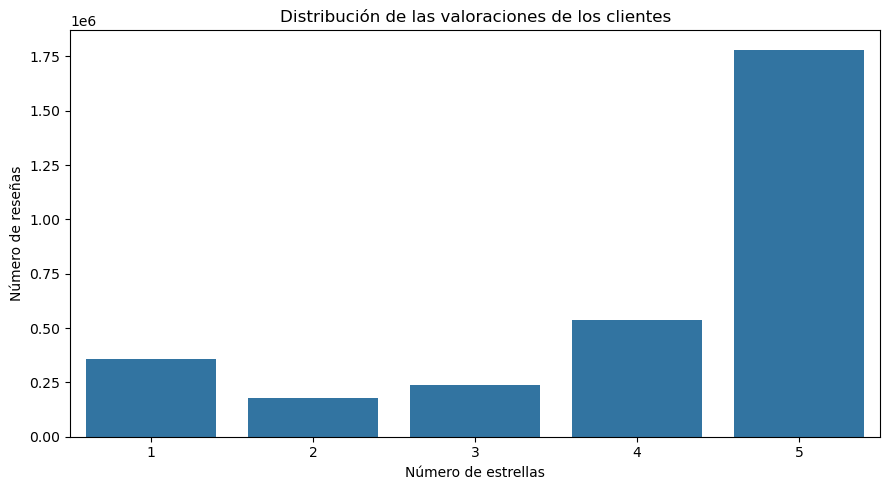

In [13]:
# Conversión de los resultados agregados a Pandas para su visualización

rating_pd = rating_distribution.toPandas()

plt.figure(figsize=(9, 5))

sns.barplot(
    data=rating_pd,
    x="star_rating",
    y="count"
)

plt.title("Distribución de las valoraciones de los clientes")
plt.xlabel("Número de estrellas")
plt.ylabel("Número de reseñas")

plt.tight_layout()
plt.show()

### 3.2. Análisis de productos

Se identifican los diez productos con mayor número de reseñas.

Para cada producto se calcula:

- El número total de reseñas.
- La valoración media recibida.

Este análisis permite conocer qué productos concentran una mayor actividad de opiniones y cuál es la valoración media de sus clientes.

In [14]:
# Diez productos con mayor número de reseñas

top_products = (
    df_reviews
    .groupBy("product_id")
    .agg(
        F.count("*").alias("total_reviews"),
        F.avg("star_rating").alias("avg_rating")
    )
    .orderBy(F.desc("total_reviews"))
    .limit(10)
)

top_products.show(truncate=False)

+----------+-------------+-----------------+
|product_id|total_reviews|avg_rating       |
+----------+-------------+-----------------+
|B003L1ZYYM|15348        |4.710125097732604|
|B0002L5R78|11168        |4.462750716332378|
|B003EM8008|9780         |4.3640081799591  |
|B0012S4APK|9365         |4.414628937533369|
|B0001FTVEK|8799         |4.034208432776452|
|B000WYVBR0|7847         |4.579711991844017|
|B0019EHU8G|7586         |4.748615871341945|
|B00F5NE2KG|6704         |4.271628878281623|
|B004QK7HI8|6539         |4.091145435081817|
|B00D5Q75RC|6075         |4.721810699588477|
+----------+-------------+-----------------+



### 3.3. Análisis temporal

Se analiza la evolución de las reseñas a lo largo del tiempo.

A partir de la fecha de publicación se extraen el año y el mes. Posteriormente, se calcula el número de reseñas y la valoración media para cada periodo.

In [15]:
# Conversión de la fecha y extracción de año y mes

df_temporal = (
    df_reviews
    .withColumn(
        "review_date_parsed",
        F.to_date(F.col("review_date"), "yyyy-MM-dd")
    )
    .filter(F.col("review_date_parsed").isNotNull())
    .withColumn("year", F.year("review_date_parsed"))
    .withColumn("month", F.month("review_date_parsed"))
)

# Agregación por año y mes

monthly_analysis = (
    df_temporal
    .groupBy("year", "month")
    .agg(
        F.count("*").alias("total_reviews"),
        F.avg("star_rating").alias("avg_rating")
    )
    .orderBy("year", "month")
)

monthly_analysis.show(20)

+----+-----+-------------+------------------+
|year|month|total_reviews|        avg_rating|
+----+-----+-------------+------------------+
|1999|    6|           18|3.4444444444444446|
|1999|    7|           84| 3.642857142857143|
|1999|    8|           47|3.9574468085106385|
|1999|    9|           64|            4.0625|
|1999|   10|           92| 4.054347826086956|
|1999|   11|          132| 3.984848484848485|
|1999|   12|          264| 3.878787878787879|
|2000|    1|          294|3.8877551020408165|
|2000|    2|          203|  3.87192118226601|
|2000|    3|          248|3.8266129032258065|
|2000|    4|          261|3.8544061302681993|
|2000|    5|          343|3.9679300291545188|
|2000|    6|          660| 4.113636363636363|
|2000|    7|          454| 4.094713656387666|
|2000|    8|          380| 3.955263157894737|
|2000|    9|          301| 3.857142857142857|
|2000|   10|          339| 3.982300884955752|
|2000|   11|          384| 4.005208333333333|
|2000|   12|          576|3.899305

## 4. Preparación de datos e ingeniería de características

Antes de aplicar algoritmos de aprendizaje automático, es necesario limpiar y transformar el contenido textual de las reseñas.

Las operaciones realizadas son:

1. Conversión del texto a minúsculas.
2. Eliminación de caracteres distintos de letras y espacios.
3. Eliminación de registros sin texto válido.
4. Creación de una variable binaria que representa el sentimiento.

Se establece la siguiente correspondencia entre la valoración original y la etiqueta de sentimiento:

- Valoraciones de 3, 4 o 5 estrellas: sentimiento positivo (`1`).
- Valoraciones de 1 o 2 estrellas: sentimiento negativo (`0`).

Esta definición permite plantear el problema como una tarea de clasificación binaria.

In [16]:
# Limpieza del texto y creación de la variable objetivo

df_clean = (
    df_reviews
    .withColumn(
        "text",
        F.lower(
            F.regexp_replace(
                F.col("review_body"),
                r"[^a-zA-Z\s]",
                " "
            )
        )
    )
    .withColumn(
        "sentiment",
        F.when(F.col("star_rating") >= 3, 1).otherwise(0)
    )
    .filter(F.col("text").isNotNull())
    .filter(F.trim(F.col("text")) != "")
    .select(
        "text",
        "star_rating",
        "sentiment"
    )
    .cache()
)

total_clean_reviews = df_clean.count()

print(f"Reseñas después de la limpieza: {total_clean_reviews:,}")

df_clean.show(10, truncate=100)

Reseñas después de la limpieza: 3,092,771
+----------------------------------------------------------------------------------------------------+-----------+---------+
|                                                                                                text|star_rating|sentiment|
+----------------------------------------------------------------------------------------------------+-----------+---------+
|                                                                                       as described |          5|        1|
|                                                                            it works as advertising |          5|        1|
|                                                                                         works pissa|          5|        1|
|                                                                                did not work at all |          1|        0|
|                 works well  bass is somewhat lacking but is present  overall plea

### 4.1. Distribución de las clases de sentimiento

Se analiza la distribución de las etiquetas positivas y negativas para conocer el equilibrio entre ambas clases.

Esta información es importante para interpretar posteriormente los resultados de los modelos de clasificación.

In [17]:
# Recuento de reseñas positivas y negativas

sentiment_distribution = (
    df_clean
    .groupBy("sentiment")
    .count()
    .orderBy("sentiment")
)

sentiment_distribution.show()

+---------+-------+
|sentiment|  count|
+---------+-------+
|        0| 537218|
|        1|2555553|
+---------+-------+



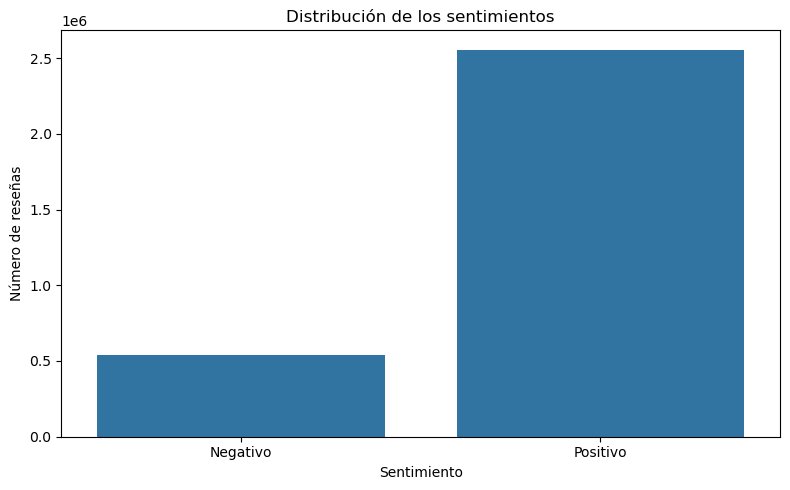

In [18]:
# Visualización de la distribución de sentimientos

sentiment_pd = sentiment_distribution.toPandas()

sentiment_pd["sentiment_label"] = (
    sentiment_pd["sentiment"]
    .map({
        0: "Negativo",
        1: "Positivo"
    })
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=sentiment_pd,
    x="sentiment_label",
    y="count"
)

plt.title("Distribución de los sentimientos")
plt.xlabel("Sentimiento")
plt.ylabel("Número de reseñas")

plt.tight_layout()
plt.show()

### 4.2. Muestreo del conjunto de datos

El conjunto de datos contiene millones de registros. Para facilitar la experimentación con los modelos de aprendizaje automático, se genera una muestra aleatoria del 1 %.

Se utiliza una semilla fija para que el muestreo sea reproducible.

In [19]:
# Generación de una muestra aleatoria del 1 %

df_sample = (
    df_clean
    .sample(
        withReplacement=False,
        fraction=0.01,
        seed=2022
    )
    .cache()
)

sample_size = df_sample.count()

print(f"Tamaño de la muestra: {sample_size:,}")

Tamaño de la muestra: 30,903


In [20]:
# División de la muestra en conjuntos de entrenamiento y prueba

df_train, df_test = df_sample.randomSplit(
    [0.8, 0.2],
    seed=2022
)

print(f"Registros de entrenamiento: {df_train.count():,}")
print(f"Registros de prueba: {df_test.count():,}")

Registros de entrenamiento: 24,715
Registros de prueba: 6,188


## 5. Construcción del flujo de aprendizaje automático

Se implementa un flujo de procesamiento de texto mediante Spark ML.

El flujo incluye las siguientes etapas:

1. **Tokenización:** división de cada reseña en palabras o términos.
2. **Eliminación de palabras vacías:** supresión de términos frecuentes con escaso valor informativo.
3. **HashingTF:** transformación del texto en vectores numéricos mediante frecuencias de términos.
4. **IDF:** ponderación de los términos según su frecuencia inversa en los documentos.
5. **Clasificación:** entrenamiento de un algoritmo de aprendizaje automático a partir de las características obtenidas.

Se entrenan dos algoritmos:

- Regresión logística.
- Árbol de decisión para clasificación.

Ambos modelos utilizan los mismos conjuntos de entrenamiento y prueba para facilitar su comparación.

In [21]:
# Configuración de las etapas de procesamiento de texto

tokenizer = Tokenizer(
    inputCol="text",
    outputCol="words"
)

remover = StopWordsRemover(
    inputCol="words",
    outputCol="filtered_words"
)

hashingTF = HashingTF(
    inputCol="filtered_words",
    outputCol="raw_features",
    numFeatures=6000
)

idf = IDF(
    inputCol="raw_features",
    outputCol="features"
)

print("Etapas de procesamiento de texto configuradas.")

Etapas de procesamiento de texto configuradas.


### 5.1. Modelo de regresión logística

La regresión logística se utiliza como primer algoritmo de clasificación.

El modelo estima la probabilidad de que una reseña pertenezca a la clase positiva o negativa a partir de las características numéricas obtenidas durante el procesamiento del texto.

In [22]:
# Definición del clasificador de regresión logística

lr = LogisticRegression(
    featuresCol="features",
    labelCol="sentiment",
    maxIter=20,
    regParam=0.01
)

# Construcción del pipeline completo

pipeline_lr = Pipeline(
    stages=[
        tokenizer,
        remover,
        hashingTF,
        idf,
        lr
    ]
)

print("Pipeline de regresión logística configurado.")

Pipeline de regresión logística configurado.


In [23]:
# Entrenamiento del modelo

pipeline_lr_model = pipeline_lr.fit(df_train)

print("Modelo de regresión logística entrenado.")

Modelo de regresión logística entrenado.


In [24]:
# Predicciones sobre el conjunto de prueba

df_lr_predictions = pipeline_lr_model.transform(df_test)

df_lr_predictions.select(
    "text",
    "sentiment",
    "prediction",
    "probability"
).show(10, truncate=90)

+------------------------------------------------------------------------------------------+---------+----------+------------------------------------------+
|                                                                                      text|sentiment|prediction|                               probability|
+------------------------------------------------------------------------------------------+---------+----------+------------------------------------------+
|                                                                              not worth it|        0|       1.0|  [0.21583733708716077,0.7841626629128392]|
|                minutes to set up and easy to hang  adds quality to the projection picture|        1|       0.0|   [0.5725927795996898,0.4274072204003102]|
|  videoid         b a  ab        c  faa dc   with everything switching from the old rca...|        1|       1.0| [5.948479272321743E-4,0.9994051520727678]|
|  videoid   edc eb      a    cb a  fefbb e   this bluetoo

In [25]:
# Evaluación mediante el área bajo la curva Precision-Recall

evaluator_pr = BinaryClassificationEvaluator(
    labelCol="sentiment",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderPR"
)

lr_pr_auc = evaluator_pr.evaluate(df_lr_predictions)

print(f"PR AUC de regresión logística: {lr_pr_auc:.4f}")

PR AUC de regresión logística: 0.9588


### 5.2. Modelo de árbol de decisión

Se entrena un segundo modelo utilizando un árbol de decisión de clasificación.

Este algoritmo aprende reglas de decisión a partir de las características textuales transformadas y permite asignar cada reseña a una de las dos clases de sentimiento.

Se utiliza el mismo conjunto de prueba y la misma métrica de evaluación que en el modelo anterior.

In [26]:
# Definición del clasificador de árbol de decisión

dt = DecisionTreeClassifier(
    featuresCol="features",
    labelCol="sentiment",
    maxDepth=10
)

# Construcción del pipeline completo

pipeline_dt = Pipeline(
    stages=[
        tokenizer,
        remover,
        hashingTF,
        idf,
        dt
    ]
)

print("Pipeline de árbol de decisión configurado.")

Pipeline de árbol de decisión configurado.


In [27]:
# Entrenamiento del modelo de árbol de decisión

pipeline_dt_model = pipeline_dt.fit(df_train)

print("Modelo de árbol de decisión entrenado.")

Modelo de árbol de decisión entrenado.


In [28]:
# Predicciones sobre el conjunto de prueba

df_dt_predictions = pipeline_dt_model.transform(df_test)

df_dt_predictions.select(
    "text",
    "sentiment",
    "prediction",
    "probability"
).show(10, truncate=100)

+----------------------------------------------------------------------------------------------------+---------+----------+----------------------------------------+
|                                                                                                text|sentiment|prediction|                             probability|
+----------------------------------------------------------------------------------------------------+---------+----------+----------------------------------------+
|                                                                                        not worth it|        0|       1.0|[0.13909458737308192,0.8609054126269181]|
|                          minutes to set up and easy to hang  adds quality to the projection picture|        1|       1.0|[0.13909458737308192,0.8609054126269181]|
|  videoid         b a  ab        c  faa dc   with everything switching from the old rca plugs to ...|        1|       1.0|[0.35347432024169184,0.6465256797583081]|
|  videoid

In [29]:
# Evaluación del árbol de decisión

dt_pr_auc = evaluator_pr.evaluate(df_dt_predictions)

print(f"PR AUC de árbol de decisión: {dt_pr_auc:.4f}")

PR AUC de árbol de decisión: 0.8658


### 5.3. Comparación del rendimiento de los modelos

Se comparan los resultados obtenidos por ambos clasificadores mediante el área bajo la curva Precision-Recall (PR AUC).

Esta métrica resume la relación entre precisión y exhaustividad para distintos umbrales de clasificación.

Un valor más elevado indica un mejor rendimiento según esta métrica.

In [30]:
# Tabla comparativa de los modelos

model_comparison = pd.DataFrame({
    "Modelo": [
        "Regresión logística",
        "Árbol de decisión"
    ],
    "PR AUC": [
        lr_pr_auc,
        dt_pr_auc
    ]
})

model_comparison

,Modelo,PR AUC
0,Regresión logística,0.958849
1,Árbol de decisión,0.865830


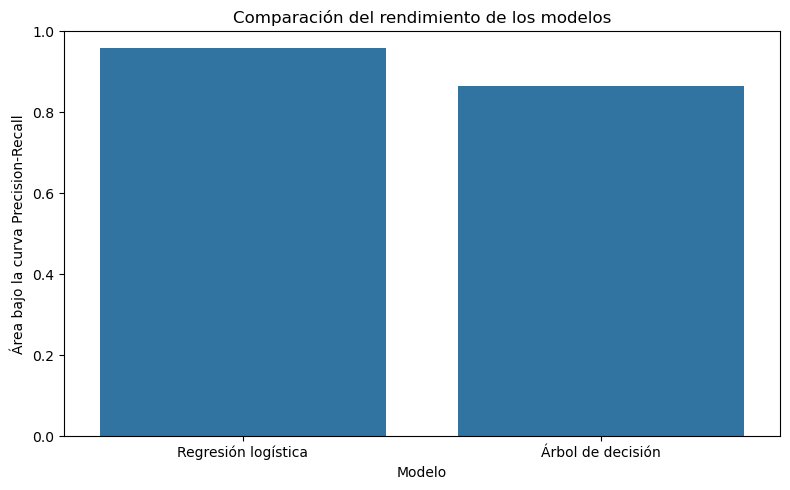

In [31]:
# Visualización comparativa de los resultados

plt.figure(figsize=(8, 5))

sns.barplot(
    data=model_comparison,
    x="Modelo",
    y="PR AUC"
)

plt.title("Comparación del rendimiento de los modelos")
plt.ylim(0, 1)
plt.ylabel("Área bajo la curva Precision-Recall")

plt.tight_layout()
plt.show()

## 6. Persistencia de modelos en Amazon S3

Una vez completados el entrenamiento y la evaluación, los modelos se guardan en Amazon S3 utilizando los mecanismos de persistencia de Apache Spark ML.

Se almacena cada pipeline completo, incluyendo las etapas de preprocesamiento del texto, extracción de características y clasificación. Esto permite conservar tanto las transformaciones como los parámetros aprendidos durante el entrenamiento.

Posteriormente, los modelos pueden recuperarse mediante PipelineModel.load() y utilizarse para realizar nuevas predicciones sin necesidad de repetir el proceso de entrenamiento.

In [32]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("ModeloS3") \
    .config("spark.jars.packages", "org.apache.hadoop:hadoop-aws:3.5.0,software.amazon.awssdk:bundle:2.25.53") \
    .config("spark.hadoop.fs.s3a.impl", "org.apache.hadoop.fs.s3a.S3AFileSystem") \
    .config("spark.hadoop.fs.s3a.aws.credentials.provider", "software.amazon.awssdk.auth.credentials.DefaultCredentialsProvider") \
    .getOrCreate()


In [33]:
pipeline_lr_model.write() \
    .overwrite() \
    .save(S3_MODEL_PATH_LOGISTIC_REGRESSION)

print(f"Modelo de regresión logística guardado en: {S3_MODEL_PATH_LOGISTIC_REGRESSION}")

Modelo de regresión logística guardado en: s3a://lpastor-project-emr/models/sentiment_logistic_regression


In [34]:
# Almacenamiento del modelo de árbol de decisión

pipeline_dt_model.write() \
    .overwrite() \
    .save(S3_MODEL_PATH_DECISION_TREE)

print(f"Modelo de árbol de decisión guardado en: {S3_MODEL_PATH_DECISION_TREE}")

Modelo de árbol de decisión guardado en: s3a://lpastor-project-emr/models/sentiment_decision_tree


### 6.1. Recuperación del modelo

Se carga desde Amazon S3 el pipeline de clasificación basado en árbol de decisión, previamente almacenado mediante Spark ML.

La recuperación permite verificar la persistencia del modelo y comprobar que puede utilizarse para realizar predicciones sin necesidad de volver a ejecutar las etapas de entrenamiento.

In [35]:
# Carga del modelo almacenado en Amazon S3

loaded_model = PipelineModel.load(S3_MODEL_PATH_DECISION_TREE)

print("Modelo recuperado correctamente desde Amazon S3.")

Modelo recuperado correctamente desde Amazon S3.


In [36]:
# Evaluación del modelo recuperado

loaded_predictions = loaded_model.transform(df_test)

loaded_model_pr_auc = evaluator_pr.evaluate(
    loaded_predictions
)

print(f"PR AUC del modelo recuperado: {loaded_model_pr_auc:.4f}")

PR AUC del modelo recuperado: 0.8658


## 7. Inferencia sobre nuevos datos

En esta fase se utiliza el pipeline previamente entrenado y recuperado desde Amazon S3 para realizar predicciones sobre un conjunto de reseñas.

El proceso parte de los datos cargados en el entorno local, aplica el filtrado de la categoría Electronics y ejecuta las operaciones de limpieza y preparación del texto necesarias para la inferencia.

A continuación, el pipeline aplica automáticamente las transformaciones de características y el modelo de clasificación para generar las predicciones de sentimiento.

Esta etapa permite comprobar la reutilización del modelo persistido y su aplicación a nuevos lotes de datos sin repetir el entrenamiento.

In [37]:
from pathlib import Path

# Localización del conjunto de datos
PROJECT_ROOT = Path.cwd().parent
LOCAL_TSV_PATH = (
    PROJECT_ROOT / "data" / "amazon_reviews_us_Electronics_v1_00.tsv"
)

# Comprobación de la disponibilidad del archivo
if not LOCAL_TSV_PATH.exists():
    raise FileNotFoundError(
        f"No se encuentra el archivo de datos: {LOCAL_TSV_PATH}"
    )

# Lectura del conjunto de datos mediante Apache Spark
df_inference_raw = (
    spark.read
    .option("header", "true")
    .option("sep", "\t")
    .option("inferSchema", "true")
    .csv(str(LOCAL_TSV_PATH))
)

print(f"Registros disponibles para inferencia: {df_inference_raw.count():,}")

Registros disponibles para inferencia: 3,093,869


In [38]:
# Lectura del conjunto de datos para inferencia

df_batch = (
    df_raw
    .filter(F.col("product_category") == "Electronics")
)

print(f"Registros originales para inferencia: {df_batch.count():,}")


Registros originales para inferencia: 3,093,861


In [39]:
# Limpieza y preparación del conjunto de datos

df_batch_clean = (
    df_batch
    .withColumn(
        "text",
        F.lower(
            F.regexp_replace(
                F.col("review_body"),
                r"[^a-zA-Z\s]",
                " "
            )
        )
    )
    .withColumn(
        "sentiment",
        F.when(F.col("star_rating") >= 3, 1).otherwise(0)
    )
    .filter(F.col("text").isNotNull())
    .filter(F.trim(F.col("text")) != "")
    .select(
        "text",
        "star_rating",
        "sentiment"
    )
)

print(f"Registros válidos: {df_batch_clean.count():,}")

Registros válidos: 3,092,771


In [40]:
# Generación de una muestra para la inferencia

df_batch_sample = (
    df_batch_clean
    .sample(
        withReplacement=False,
        fraction=0.01,
        seed=2022
    )
    .cache()
)

print(f"Registros de la muestra: {df_batch_sample.count():,}")

Registros de la muestra: 30,903


In [41]:
# Aplicación del modelo recuperado

df_batch_predictions = loaded_model.transform(
    df_batch_sample
)

df_batch_predictions.select(
    "text",
    "star_rating",
    "sentiment",
    "prediction"
).show(20, truncate=100)

+----------------------------------------------------------------------------------------------------+-----------+---------+----------+
|                                                                                                text|star_rating|sentiment|prediction|
+----------------------------------------------------------------------------------------------------+-----------+---------+----------+
|                                                                                       as i expected|          5|        1|       1.0|
|                                                                                     works just fine|          5|        1|       1.0|
|i was a loyal  happy x   user and when it broke i found audioflood   superior technology compact ...|          5|        1|       1.0|
|i bought these to replace a different sony pair that i lost  the sound in these is awesome and we...|          5|        1|       0.0|
|not a good product  looses network constantly  

### 7.1. Evaluación de las predicciones batch

Como las reseñas contienen su valoración original, es posible comparar las predicciones del modelo con las etiquetas de sentimiento derivadas de esas valoraciones.

Se calcula el área bajo la curva Precision-Recall para evaluar el comportamiento del modelo sobre la muestra utilizada en esta fase.

In [42]:
# Evaluación de las predicciones batch

batch_pr_auc = evaluator_pr.evaluate(
    df_batch_predictions
)

print(f"PR AUC de inferencia batch: {batch_pr_auc:.4f}")

PR AUC de inferencia batch: 0.8663


## 8. Procesamiento de eventos en tiempo real con Amazon Kinesis

Además del procesamiento por lotes, la práctica original desarrollada en AWS EMR incorporó un flujo independiente de ingesta de datos en tiempo real mediante Amazon Kinesis Data Streams y Apache Spark Structured Streaming.

El objetivo era consumir eventos desde un flujo de Kinesis, inspeccionar los registros recibidos y preparar su contenido para posteriores operaciones de transformación.

La ejecución original requería un clúster EMR con el conector de Kinesis correspondiente y permisos IAM para acceder al flujo.

**Nota:** El código de este apartado documenta la implementación original en AWS EMR. No debe ejecutarse en el entorno local de esta reconstrucción, ya que el conector Kinesis utilizado originalmente no es compatible directamente con la versión local de Spark.


In [43]:
# Configuración del flujo de Kinesis

STREAM_NAME = "real-time-kinesis-stream"

# Región de AWS donde se encuentra el flujo

AWS_REGION = "us-east-1"

print(f"Flujo Kinesis: {STREAM_NAME}")
print(f"Región de AWS: {AWS_REGION}")

Flujo Kinesis: real-time-kinesis-stream
Región de AWS: us-east-1


### 8.1. Lectura del flujo de Kinesis

Se configura Spark Structured Streaming para consumir eventos desde Amazon Kinesis Data Streams.

La posición inicial `trim_horizon` solicita la lectura desde el registro más antiguo que todavía esté disponible dentro del periodo de retención del flujo.

Los registros recibidos incluyen el contenido binario del evento y metadatos como la clave de partición, el número de secuencia y la fecha aproximada de llegada.


##### **Lectura del flujo de eventos desde Amazon Kinesis** #####
###### **Código de la práctica original ejecutada en AWS EMR** ######
```
kinesis_stream = (

    spark.readStream
    .format("kinesis")
    .option("streamName", STREAM_NAME)
    .option("region", AWS_REGION)
    .option("startingPosition", "trim_horizon")
    .load()
)

```


### 8.2. Inspección de los eventos recibidos

Para inspeccionar los eventos recibidos se utiliza un destino de tipo memoria (`memory sink`).

Este destino permite consultar temporalmente los registros desde Spark SQL durante la ejecución del notebook.

Se utiliza con fines de comprobación y desarrollo. No constituye un almacenamiento persistente para un sistema productivo.

##### Inspección de la estructura de los registros recibidos #####

```
kinesis_stream.printSchema()
```

##### Inicio de la consulta de streaming con destino en memoria #####
```
stream = (
    kinesis_stream.writeStream
    .format("memory")
    .queryName("kinesis10")
    .start()
)

print("Consulta activa:", stream.isActive)
```

##### Consulta de los eventos recibidos desde Kinesis #####
```
spark.sql("""
    SELECT *
    FROM kinesis10
""").show(truncate=False)
```
##### Número de eventos disponibles en la tabla temporal #####
```
spark.table("kinesis10").count()
```

##### Inicio de la consulta de streaming con destino en memoria #####

```
stream = (
    kinesis_stream.writeStream
    .format("memory")
    .queryName("kinesis10")
    .start()
)

print("Consulta activa:", stream.isActive)
```

##### Consulta de los eventos recibidos desde Kinesis #####
```
spark.sql("""
    SELECT *
    FROM kinesis10
""").show(truncate=False)
```
##### Número de eventos disponibles en la tabla temporal #####
```
spark.table("kinesis10").count()
```

### 8.3. Finalización de la consulta de inspección

Una vez inspeccionados los eventos, se detiene la primera consulta de streaming.

Esto permite liberar los recursos asociados y continuar con el siguiente flujo de transformación.

##### Detención de la consulta de inspección #####
```
stream.stop()
```
##### Comprobación de las consultas de streaming activas #####
```
spark.streams.active
```

##### Detención de cualquier consulta que permanezca activa #####
```
for active_query in spark.streams.active:
    active_query.stop()
```

## 9. Procesamiento de mensajes JSON y análisis de sentimiento

Esta fase implementa un flujo de procesamiento de eventos integrado con **Amazon Kinesis Data Streams** y **Amazon Comprehend** para analizar mensajes recibidos en tiempo real.

Los eventos procedentes de Kinesis se reciben en la columna `data` en formato binario. El flujo convierte este contenido a texto y, posteriormente, interpreta su estructura JSON mediante el esquema definido para los mensajes de entrada.

Cada mensaje contiene un campo `text`, del que se extrae el contenido textual que será enviado al servicio **Amazon Comprehend** para realizar el análisis de sentimiento.

Comprehend procesa el texto y devuelve la categoría de sentimiento identificada, junto con las puntuaciones asociadas a cada categoría. Esta información se incorpora al flujo como nuevos campos, enriqueciendo los eventos originales con información sobre su polaridad.

El resultado es un flujo de eventos estructurados que combina la ingesta continua de datos, la interpretación de mensajes JSON y el análisis de sentimiento mediante servicios de AWS.

##### Definición del esquema de los mensajes JSON #####
```
MESSAGE_SCHEMA = StructType([
    StructField("text", StringType(), True)
])

print("Esquema de los mensajes JSON definido.")
```

### 9.1. Decodificación y análisis de los mensajes JSON

Los eventos recibidos desde Amazon Kinesis Data Streams contienen el mensaje en la columna `data`, codificado en formato binario.

En esta etapa, el contenido se convierte a una cadena de texto y se interpreta mediante `from_json()`, utilizando el esquema definido previamente.

Una vez decodificado el mensaje, se extrae el campo `text` y se conservan los metadatos del evento, como el nombre del flujo, la clave de partición, el número de secuencia y la marca temporal de recepción.

Finalmente, se descartan los registros que no contienen texto válido para las siguientes etapas del procesamiento.

##### Conversión del contenido binario y extracción del mensaje JSON #####
```
parsed_stream = (
    kinesis_stream
    .select(
        F.col("data").cast("string").alias("json_data"),
        "streamName",
        "partitionKey",
        "sequenceNumber",
        "approximateArrivalTimestamp"
    )
    .withColumn(
        "message",
        F.from_json(
            F.col("json_data"),
            MESSAGE_SCHEMA
        )
    )
    .select(
        F.col("message.text").alias("text"),
        "streamName",
        "partitionKey",
        "sequenceNumber",
        "approximateArrivalTimestamp"
    )
    .filter(F.col("text").isNotNull())
)

parsed_stream.printSchema()
```

### 9.2. Integración con Amazon Comprehend

El análisis de sentimiento de los mensajes se realiza mediante **Amazon Comprehend**, un servicio gestionado de AWS para el procesamiento del lenguaje natural.

La integración utiliza la operación `DetectSentiment`, que permite identificar la polaridad del texto y obtener las puntuaciones correspondientes a las categorías `POSITIVE`, `NEGATIVE`, `NEUTRAL` y `MIXED`.

Las llamadas al servicio se realizan desde Python mediante **Boto3**, el SDK de AWS. Para su ejecución, el entorno debe disponer de credenciales y permisos IAM que autoricen el acceso a Amazon Comprehend.

La respuesta del servicio se incorpora al procesamiento de los eventos, enriqueciendo cada mensaje con información sobre su sentimiento y las puntuaciones obtenidas.

Para operar con volúmenes elevados de eventos, es importante contemplar mecanismos de gestión de errores, reintentos, control de la frecuencia de llamadas y optimización de costes.

##### Creación del cliente de Amazon Comprehend ##### 
```
comprehend = boto3.client(
    "comprehend",
    region_name=AWS_REGION
)


def detect_sentiment(text):
    """
    Detecta el sentimiento de un texto mediante Amazon Comprehend.
    """

    if text is None or not text.strip():
        return None

    try:
        response = comprehend.detect_sentiment(
            Text=text[:4500],
            LanguageCode="en"
        )

        return response["Sentiment"]

    except Exception as error:
        print(f"Error durante el análisis de sentimiento: {error}")
        return None
```

##### Registro de la función como UDF de Spark #####
```
detect_sentiment_udf = udf(
    detect_sentiment,
    StringType()
)

print("Función UDF de análisis de sentimiento registrada.")
```

### 9.3. Aplicación del análisis de sentimiento al flujo

La función de análisis de sentimiento se aplicaba a cada mensaje extraído del flujo de Kinesis.

El resultado incorporaba una nueva columna denominada comprehend_sentiment, que contenía la categoría de sentimiento devuelta por Amazon Comprehend.

##### Enriquecimiento de los mensajes con el sentimiento detectado #####
```
sentiment_stream = (
    parsed_stream
    .withColumn(
        "comprehend_sentiment",
        detect_sentiment_udf(F.col("text"))
    )
)

sentiment_stream.printSchema()
```

### 9.4. Inicio del procesamiento de sentimiento en streaming

Los eventos enriquecidos se escribían en una tabla temporal de memoria para poder consultar los mensajes y las etiquetas de sentimiento generadas.

La consulta se iniciaba como un proceso de streaming continuo.

##### Inicio de la consulta de análisis de sentimiento #####
```
sentiment_query = (
    sentiment_stream
    .writeStream
    .format("memory")
    .queryName("sentiment_messages")
    .start()
)

print(
    f"Consulta de sentimiento activa: "
    f"{sentiment_query.isActive}"
)
```

##### Inspección de los mensajes procesados #####
```
spark.table("sentiment_messages").show(
    20,
    truncate=False
)
```

##### Recuento de mensajes procesados #####
```
processed_messages = spark.table(
    "sentiment_messages"
).count()

print(f"Mensajes procesados: {processed_messages}")
```

### 9.5. Finalización de la consulta de streaming

Una vez inspeccionados los resultados, se detiene la consulta.

El destino de memoria permite validar el procesamiento durante la ejecución del notebook. Para un entorno productivo sería necesario utilizar un destino persistente, por ejemplo Amazon S3, una base de datos u otro sistema de almacenamiento o mensajería.

##### Detención de la consulta de análisis de sentimiento #####
```
sentiment_query.stop()

print(
    f"Consulta activa después de detenerla: "
    f"{sentiment_query.isActive}"
)
```

## 10. Simulación local de Structured Streaming

En esta fase se implementa un flujo de procesamiento de eventos en tiempo real utilizando Apache Spark Structured Streaming en un entorno local.

La simulación permite generar eventos de forma continua, representar los mensajes en formato JSON, decodificar su contenido y aplicar un proceso de análisis de sentimiento mediante una función definida por el usuario (UDF) en Python.

El flujo de procesamiento comprende las siguientes etapas:

1. **Generación de eventos:** utilización de la fuente `rate` de Spark para producir eventos de forma continua.
2. **Construcción de mensajes:** generación de mensajes JSON con contenido textual.
3. **Decodificación:** interpretación de los mensajes JSON mediante `from_json()` y extracción del texto.
4. **Análisis de sentimiento:** aplicación de una función UDF que clasifica los mensajes como positivos, negativos o neutros.
5. **Visualización de resultados:** utilización de un destino de tipo `memory` para consultar los resultados generados por el flujo de streaming.

Esta implementación permite verificar el funcionamiento del procesamiento continuo de eventos y la integración de transformaciones personalizadas en Spark Structured Streaming, sin depender de servicios externos de AWS.

La clasificación local utiliza un mecanismo basado en palabras clave y tiene como finalidad procesar los mensajes de la simulación. No sustituye al análisis de sentimiento proporcionado por Amazon Comprehend.

In [44]:
import pyspark

from pyspark.sql import functions as F

# Información del entorno de ejecución
print(f"Versión de PySpark: {pyspark.__version__}")
print(f"Versión de Apache Spark: {spark.version}")
print(
    "Versión de Java:",
    spark.sparkContext._jvm.java.lang.System.getProperty("java.version")
)

# Generación continua de eventos mediante la fuente rate
events = (
    spark.readStream
    .format("rate")
    .option("rowsPerSecond", 2)
    .load()
)

# Construcción de mensajes JSON simulando eventos de entrada
stream_events = events.select(
    F.encode(
        F.to_json(
            F.struct(
                F.col("value").cast("string").alias("text")
            )
        ),
        "UTF-8"
    ).alias("data"),
    F.col("timestamp")
)

# Comprobación de la estructura del flujo
print("Esquema del flujo de eventos:")
stream_events.printSchema()

Versión de PySpark: 4.2.0
Versión de Apache Spark: 4.2.0
Versión de Java: 21.0.13
Esquema del flujo de eventos:
root
 |-- data: binary (nullable = true)
 |-- timestamp: timestamp (nullable = true)



In [45]:
# Inicio del flujo y almacenamiento temporal de eventos
events_query = (
    stream_events
    .writeStream
    .format("memory")
    .queryName("local_events")
    .outputMode("append")
    .start()
)

print("Estado del flujo:", "Activo" if events_query.isActive else "Inactivo")

Estado del flujo: Activo


In [46]:
# Consulta de los eventos generados
df_local_events = spark.sql("""
    SELECT
        timestamp,
        CAST(data AS STRING) AS json_data
    FROM local_events
""")

df_local_events.show(truncate=False)

+---------+---------+
|timestamp|json_data|
+---------+---------+
+---------+---------+



In [47]:
from pyspark.sql.types import (
    StructType,
    StructField,
    StringType
)

# Definición del esquema de los mensajes JSON
MESSAGE_SCHEMA = StructType([
    StructField("text", StringType(), True)
])

In [48]:
# Decodificación de los mensajes JSON y extracción del texto

df_stream_decoded = (
    stream_events
    .withColumn(
        "json_data",
        F.col("data").cast("string")
    )
    .withColumn(
        "parsed_data",
        F.from_json(F.col("json_data"), MESSAGE_SCHEMA)
    )
    .select(
        "timestamp",
        F.col("parsed_data.text").alias("text")
    )
)

# Comprobación de la estructura del flujo decodificado
df_stream_decoded.printSchema()

root
 |-- timestamp: timestamp (nullable = true)
 |-- text: string (nullable = true)



In [49]:
# Inicio del flujo de eventos decodificados
decoded_query = (
    df_stream_decoded
    .writeStream
    .format("memory")
    .queryName("decoded_events")
    .outputMode("append")
    .start()
)

print(
    "Estado de la consulta:",
    "Activa" if decoded_query.isActive else "Inactiva"
)

Estado de la consulta: Activa


In [50]:
# Consulta de los mensajes JSON decodificados
df_decoded_events = spark.sql("""
    SELECT
        timestamp,
        text
    FROM decoded_events
""")

df_decoded_events.show(20, truncate=False)

+---------+----+
|timestamp|text|
+---------+----+
+---------+----+



In [51]:
# Detención de las consultas de streaming
events_query.stop()
decoded_query.stop()

print("Consultas de streaming detenidas correctamente.")

Consultas de streaming detenidas correctamente.


In [52]:
def classify_sentiment_local(text):
    """
    Clasifica el sentimiento de un texto mediante un análisis
    basado en palabras clave positivas y negativas.

    Returns:
        str: POSITIVE, NEGATIVE, NEUTRAL o UNKNOWN.
    """

    if text is None:
        return "UNKNOWN"

    positive_words = {
        "good", "great", "excellent", "love",
        "amazing", "happy", "wonderful", "best"
    }

    negative_words = {
        "bad", "terrible", "poor", "hate",
        "awful", "disappointed", "worst", "broken"
    }

    words = set(text.lower().split())

    positive_score = len(words & positive_words)
    negative_score = len(words & negative_words)

    if positive_score > negative_score:
        return "POSITIVE"
    elif negative_score > positive_score:
        return "NEGATIVE"
    else:
        return "NEUTRAL"

In [53]:
# Mensajes de entrada para la simulación de streaming

SAMPLE_MESSAGES = [
    '{"text":"This product is excellent and amazing"}',
    '{"text":"The quality is terrible and poor"}',
    '{"text":"I love this product"}',
    '{"text":"The product is broken"}',
    '{"text":"This is an ordinary product"}',
    '{"text":"Great quality and wonderful experience"}',
    '{"text":"I am disappointed with this purchase"}'
]

print(f"Número de mensajes preparados: {len(SAMPLE_MESSAGES)}")

Número de mensajes preparados: 7


In [54]:
# Creación de un DataFrame con los mensajes de entrada

df_messages = spark.createDataFrame(
    [(message,) for message in SAMPLE_MESSAGES],
    ["json_data"]
)

# Comprobación de los mensajes preparados
df_messages.show(truncate=False)

+-------------------------------------------------+
|json_data                                        |
+-------------------------------------------------+
|{"text":"This product is excellent and amazing"} |
|{"text":"The quality is terrible and poor"}      |
|{"text":"I love this product"}                   |
|{"text":"The product is broken"}                 |
|{"text":"This is an ordinary product"}           |
|{"text":"Great quality and wonderful experience"}|
|{"text":"I am disappointed with this purchase"}  |
+-------------------------------------------------+



In [55]:
# Generación continua de eventos
message_source = (
    spark.readStream
    .format("rate")
    .option("rowsPerSecond", 2)
    .load()
)

# Construcción del conjunto de mensajes de entrada
messages_array = F.array(
    *[F.lit(message) for message in SAMPLE_MESSAGES]
)

# Asociación de cada evento con un mensaje de entrada
df_messages_stream = (
    message_source
    .withColumn(
        "json_data",
        F.element_at(
            messages_array,
            (F.col("value") % len(SAMPLE_MESSAGES) + 1).cast("int")
        )
    )
    .select(
        "timestamp",
        "json_data"
    )
)

# Comprobación de la estructura del flujo
df_messages_stream.printSchema()

root
 |-- timestamp: timestamp (nullable = true)
 |-- json_data: string (nullable = false)



In [56]:
# Decodificación de mensajes JSON en columnas estructuradas

df_messages_decoded = (
    df_messages_stream
    .withColumn(
        "parsed_data",
        F.from_json(F.col("json_data"), MESSAGE_SCHEMA)
    )
    .select(
        "timestamp",
        F.col("parsed_data.text").alias("text")
    )
)

# Comprobación de la estructura del flujo decodificado
df_messages_decoded.printSchema()

root
 |-- timestamp: timestamp (nullable = true)
 |-- text: string (nullable = true)



In [57]:
from pyspark.sql.types import StringType

# Registrar la función de clasificación como UDF de Spark
sentiment_udf = F.udf(
    classify_sentiment_local,
    StringType()
)

# Aplicar el análisis de sentimiento al flujo
df_sentiment_stream = (
    df_messages_decoded
    .withColumn(
        "sentiment",
        sentiment_udf(F.col("text"))
    )
)

df_sentiment_stream.printSchema()


root
 |-- timestamp: timestamp (nullable = true)
 |-- text: string (nullable = true)
 |-- sentiment: string (nullable = true)



### 10.1. Clasificación de sentimiento mediante UDF

In [58]:
from pyspark.sql.types import StringType

# Registro de la función de clasificación como UDF de Spark
sentiment_udf = F.udf(
    classify_sentiment_local,
    StringType()
)

# Aplicación de la clasificación de sentimiento al flujo
df_sentiment_stream = (
    df_messages_decoded
    .withColumn(
        "sentiment",
        sentiment_udf(F.col("text"))
    )
)

# Comprobación de la estructura del flujo clasificado
df_sentiment_stream.printSchema()

root
 |-- timestamp: timestamp (nullable = true)
 |-- text: string (nullable = true)
 |-- sentiment: string (nullable = true)



In [59]:
# Inicio del flujo de clasificación de sentimiento
sentiment_query = (
    df_sentiment_stream
    .writeStream
    .format("memory")
    .queryName("sentiment_results")
    .outputMode("append")
    .start()
)

print(
    "Estado del flujo:",
    "Activo" if sentiment_query.isActive else "Inactivo"
)

Estado del flujo: Activo


### 10.2. Consulta de resultados del análisis de sentimiento

Los resultados del procesamiento continuo se almacenan temporalmente en una tabla en memoria de Spark.

Esta consulta permite inspeccionar los mensajes procesados y comprobar la clasificación de sentimiento asignada a cada uno.

In [60]:
# Finalización de la consulta de Structured Streaming

sentiment_query.stop()

print(
    "Estado final de la consulta:",
    "Detenida" if not sentiment_query.isActive else "Activa"
)

Estado final de la consulta: Detenida


## 11. Resultados y conclusiones

El proyecto integra diferentes tecnologías de ingeniería de datos, procesamiento distribuido y aprendizaje automático dentro del ecosistema de Apache Spark y AWS.

### Procesamiento por lotes (Batch Processing)

Se ha desarrollado un flujo de procesamiento de datos que comprende las siguientes operaciones:

- Ingesta y lectura de datos de reseñas de Amazon en formato TSV.
- Filtrado de registros correspondientes a la categoría `Electronics`.
- Análisis exploratorio de valoraciones, productos y evolución temporal.
- Limpieza y transformación de datos textuales.
- Generación de etiquetas binarias para la clasificación del sentimiento.
- Extracción de características mediante `Tokenizer`, `StopWordsRemover`, `HashingTF` e `IDF`.
- Entrenamiento de modelos de clasificación mediante regresión logística y árbol de decisión.
- Evaluación del rendimiento de los modelos mediante métricas de clasificación y área bajo la curva Precision-Recall.
- Persistencia de los pipelines entrenados en Amazon S3.
- Recuperación de modelos almacenados y ejecución de inferencias sobre conjuntos de datos.

### Procesamiento de eventos en tiempo real (Streaming)

Se ha implementado un flujo de procesamiento de eventos mediante Apache Spark Structured Streaming, integrado con servicios de AWS:

- Ingesta de eventos desde Amazon Kinesis Data Streams.
- Procesamiento continuo mediante Spark Structured Streaming.
- Conversión de datos binarios a cadenas de texto.
- Decodificación e interpretación de mensajes JSON.
- Extracción del contenido textual y conservación de los metadatos de los eventos.
- Integración con Amazon Comprehend para la detección de sentimiento.
- Enriquecimiento de los eventos con las categorías y puntuaciones de sentimiento obtenidas.

Además, se dispone de una implementación local de Structured Streaming que permite generar eventos, procesar mensajes JSON y ejecutar una clasificación de sentimiento basada en palabras clave, sin depender de los servicios externos de AWS.

### Conclusiones

La solución reúne dos enfoques complementarios de procesamiento de datos: batch y streaming.

La parte batch permite trabajar con grandes conjuntos de reseñas, realizar transformaciones distribuidas, entrenar modelos de clasificación y persistir los pipelines para su posterior reutilización.

La parte de streaming permite procesar eventos de forma continua, interpretar mensajes estructurados e integrar servicios gestionados de AWS para enriquecer la información con análisis de sentimiento.

En conjunto, el proyecto refleja el uso integrado de Apache Spark, PySpark y AWS en flujos de ingeniería de datos y aprendizaje automático, desde la ingesta y transformación hasta el almacenamiento, la inferencia y el procesamiento de eventos.

## 12. Tecnologías y competencias técnicas

## 12. Tecnologías y competencias técnicas

### Cloud y Big Data
- Amazon Web Services (AWS)
- Amazon EMR
- Amazon S3
- Amazon Kinesis Data Streams
- Amazon Comprehend
- Apache Spark
- Spark Structured Streaming

### Ingeniería de datos
- Procesamiento distribuido con Apache Spark
- Procesamiento por lotes (Batch Processing)
- Procesamiento de eventos en streaming
- Ingesta y transformación de datos
- Limpieza y preparación de datos
- Procesamiento de datos estructurados y semiestructurados
- Decodificación e interpretación de mensajes JSON
- Agregaciones y análisis exploratorio de datos
- Persistencia de datos y modelos en Amazon S3

### Machine Learning y procesamiento de texto
- PySpark ML
- Procesamiento y transformación de texto
- Tokenización y eliminación de palabras vacías
- Extracción de características mediante TF-IDF
- Regresión logística
- Árboles de decisión
- Evaluación de modelos de clasificación
- Inferencia batch
- Análisis de sentimiento
- Integración con Amazon Comprehend

### Programación y análisis de datos
- Python
- PySpark
- SQL
- Boto3
- Pandas
- NumPy
- Matplotlib
- Seaborn

In [61]:
# Liberación de los DataFrames almacenados en caché

df_clean.unpersist()
df_sample.unpersist()
df_batch_sample.unpersist()

print("Caché de los DataFrames liberada correctamente.")

Caché de los DataFrames liberada correctamente.
